**Задача 6. Затухание**
- Добавить экспоненциальное затухание света с длиной затухания 8 метров.
- Получить энергетический отклик детектора для источников с энергией 1 МэВ, расположенных в разных точках вдоль вертикальной оси детектора.
- Сравнить полученные распределения с результатами симуляции тех же источников без затухания.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from numpy import pi, sin, cos, arccos, sqrt, random, column_stack

In [2]:
class Detector:
    def __init__(self, R=2.0, N=40, r_cm=10.0, a=0.5):
        self.R = float(R)
        self.N = int(N)
        self.r = float(r_cm) / 100.0
        self.a = float(a)
        self.centers = np.zeros((self.N, 3))
        self.distribute_on_detector()

    def distribute_on_detector(self):
        golden_ratio = (1 + 5 ** 0.5) / 2
        for i in range(self.N):
            theta = 2 * pi * i / golden_ratio
            phi = arccos(1 - 2 * (i + 0.5) / self.N)
            x, y, z = self.R * cos(theta) * sin(phi), self.R * sin(theta) * sin(phi), self.R * cos(phi)
            self.centers[i] = [x, y, z]

    def is_point_on(self, point):
        point = np.array(point)
        distances = np.linalg.norm(self.centers - point, axis=1)
        result = bool(np.any(distances <= self.r))
        return result


class Source:
    def __init__(self, Y=10000):
        self.Y = float(Y)

    def generate_photons(self, E):
        expected_N = self.Y * E
        N = random.poisson(expected_N)
        cos_theta = random.uniform(-1.0, 1.0, N)
        phi = random.uniform(0.0, 2 * pi, N)
        sin_theta = sqrt(1.0 - cos_theta ** 2)
        x, y, z = sin_theta * cos(phi), sin_theta * sin(phi), cos_theta
        directions = column_stack((x, y, z))
        return directions


def track_photon_to_boundary(start_pos, direction, detector):
    x0, y0, z0 = start_pos
    nx, ny, nz = direction
    a_coef = 1.0
    b_coef = 2.0 * (x0 * nx + y0 * ny + z0 * nz)
    c_coef = (x0 ** 2 + y0 ** 2 + z0 ** 2) - detector.R ** 2
    discriminant = b_coef ** 2 - 4.0 * a_coef * c_coef
    sqrt_disc = np.sqrt(discriminant)
    t1 = (-b_coef + sqrt_disc) / (2.0 * a_coef)
    t2 = (-b_coef - sqrt_disc) / (2.0 * a_coef)
    valid_t = [t for t in (t1, t2) if t > 0]
    t_hit = min(valid_t)
    hit_point = (x0 + t_hit * nx, y0 + t_hit * ny, z0 + t_hit * nz)
    result_is_point_on = detector.is_point_on(hit_point)
    return result_is_point_on


def generate_photoelectrons(mean_a):
    photoelectrons = np.random.poisson(mean_a)
    return photoelectrons


def simulate_events(E, num_events, start_pos, detector, source):
    charges = np.zeros(num_events)
    for i in range(num_events):
        directions = source.generate_photons(E)
        q_event = 0
        for direction in directions:
            if track_photon_to_boundary(start_pos, direction, detector):
                q_event += random.poisson(detector.a)
        charges[i] = q_event
    return charges

In [3]:
ATTENUATION_LENGTH = 8.0

def track_photon_to_boundary_attenuated(start_pos, direction, detector, attenuation_length):
    x0, y0, z0 = start_pos
    nx, ny, nz = direction

    a_coef = 1.0
    b_coef = 2.0 * (x0 * nx + y0 * ny + z0 * nz)
    c_coef = (x0 ** 2 + y0 ** 2 + z0 ** 2) - detector.R ** 2

    discriminant = b_coef ** 2 - 4.0 * a_coef * c_coef
    sqrt_disc = np.sqrt(discriminant)
    t1 = (-b_coef + sqrt_disc) / (2.0 * a_coef)
    t2 = (-b_coef - sqrt_disc) / (2.0 * a_coef)

    valid_t = [t for t in (t1, t2) if t > 0]
    t_hit = min(valid_t)
    distance = t_hit

    survival_prob = np.exp(-distance / attenuation_length)
    survived = bool(random.random() < survival_prob)

    if not survived:
        return False, False, distance

    hit_point = (x0 + t_hit * nx, y0 + t_hit * ny, z0 + t_hit * nz)
    hits_pmt = detector.is_point_on(hit_point)
    
    return hits_pmt, True, distance


def simulate_events_attenuated(E, num_events, start_pos, detector, source, attenuation_length):
    charges = np.zeros(num_events)
    for i in range(num_events):
        directions = source.generate_photons(E)
        q_event = 0
        for direction in directions:
            hits_pmt, survived, distance = track_photon_to_boundary_attenuated(
                start_pos, direction, detector, attenuation_length
            )
            if hits_pmt:
                q_event += random.poisson(detector.a)
        charges[i] = q_event
    return charges

In [4]:
detector = Detector(R=2.0, N=40, r_cm=10.0, a=0.5)
source = Source(Y=10000)
center = [0.0, 0.0, 0.0]
test_direction = np.array([0.0, 0.0, 1.0])

In [5]:
_, _, d = track_photon_to_boundary_attenuated(center, test_direction, detector, ATTENUATION_LENGTH)
assert abs(d - detector.R) < 1e-9, f"ожидалось d=R={detector.R}, получено {d}"
print(f"PASS: фотон из центра пролетает ровно R={detector.R} м до стенки.")

PASS: фотон из центра пролетает ровно R=2.0 м до стенки.


In [6]:
expected_survival_center = np.exp(-detector.R / ATTENUATION_LENGTH)
print(f"вероятность выживания фотона из центра: exp(-{detector.R}/{ATTENUATION_LENGTH}) = {expected_survival_center:.4f}")

вероятность выживания фотона из центра: exp(-2.0/8.0) = 0.7788


In [7]:
np.random.seed(2024)

z_positions = [0.0, 0.5, 1.0, 1.5, 1.9]
E_fixed = 1.0
n_events = 300

results_no_att = {}
results_att = {}

t_start = time.perf_counter()
for z in z_positions:
    start_pos = [0.0, 0.0, z]

    t0 = time.perf_counter()
    charges_no_att = simulate_events(E_fixed, n_events, start_pos, detector, source)
    results_no_att[z] = charges_no_att
    t1 = time.perf_counter()

    charges_att = simulate_events_attenuated(E_fixed, n_events, start_pos, detector, source, ATTENUATION_LENGTH)
    results_att[z] = charges_att
    t2 = time.perf_counter()

    print(f"z={z:.1f} м  |  без затухания: mean={charges_no_att.mean():7.2f} std={charges_no_att.std():5.2f} [{t1-t0:.1f}с]  "
          f"|  с затуханием: mean={charges_att.mean():7.2f} std={charges_att.std():5.2f} [{t2-t1:.1f}с]")

print(f"\nВсего: {time.perf_counter()-t_start:.1f} с")

z=0.0 м  |  без затухания: mean= 125.00 std=13.73 [21.1с]  |  с затуханием: mean=  96.41 std=11.80 [19.8с]
z=0.5 м  |  без затухания: mean= 126.26 std=13.26 [24.5с]  |  с затуханием: mean=  96.11 std=12.30 [25.4с]
z=1.0 м  |  без затухания: mean= 124.39 std=14.32 [29.5с]  |  с затуханием: mean=  98.54 std=12.34 [30.9с]
z=1.5 м  |  без затухания: mean= 122.68 std=13.63 [32.4с]  |  с затуханием: mean= 100.73 std=12.42 [33.7с]
z=1.9 м  |  без затухания: mean=  84.35 std=11.23 [31.4с]  |  с затуханием: mean=  68.77 std=10.38 [32.0с]

Всего: 280.9 с


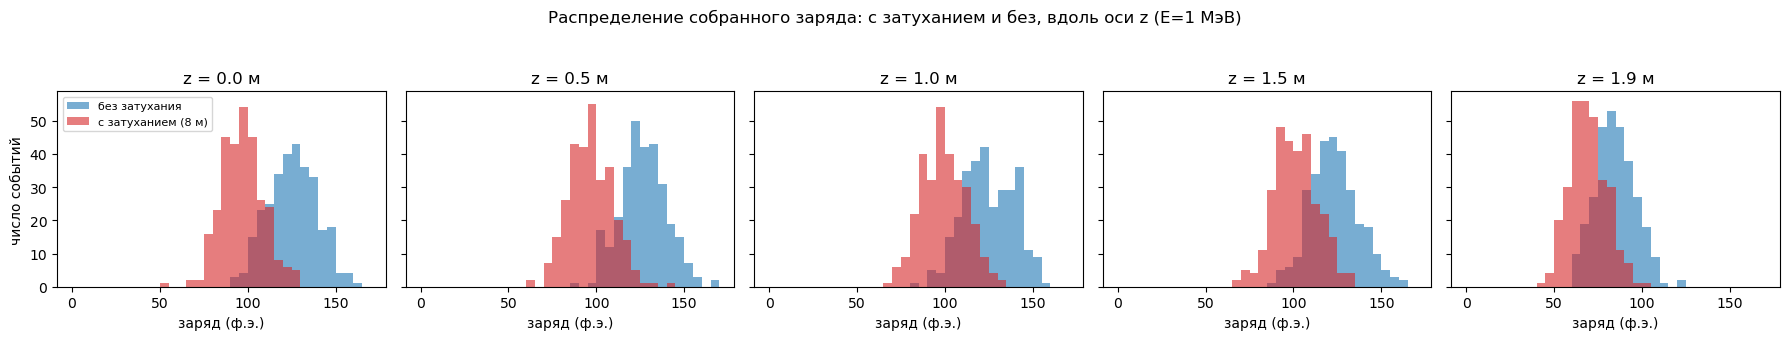

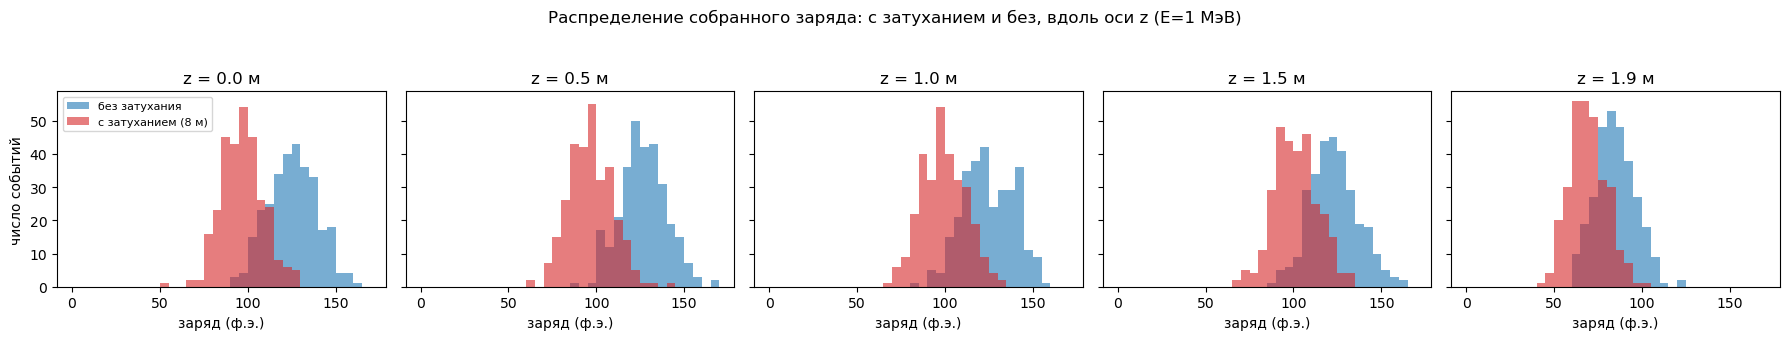

In [8]:
fig, axes = plt.subplots(1, len(z_positions), figsize=(18, 3.2), sharey=True)
bins = np.linspace(0, 170, 35)
for ax, z in zip(axes, z_positions):
    ax.hist(results_no_att[z], bins=bins, alpha=0.6, color='tab:blue', label='без затухания')
    ax.hist(results_att[z], bins=bins, alpha=0.6, color='tab:red', label='с затуханием (8 м)')
    ax.set_title(f'z = {z} м')
    ax.set_xlabel('заряд (ф.э.)')
axes[0].set_ylabel('число событий')
axes[0].legend(fontsize=8)
fig.suptitle('Распределение собранного заряда: с затуханием и без, вдоль оси z (E=1 МэВ)', y=1.05)
fig.tight_layout()
fig

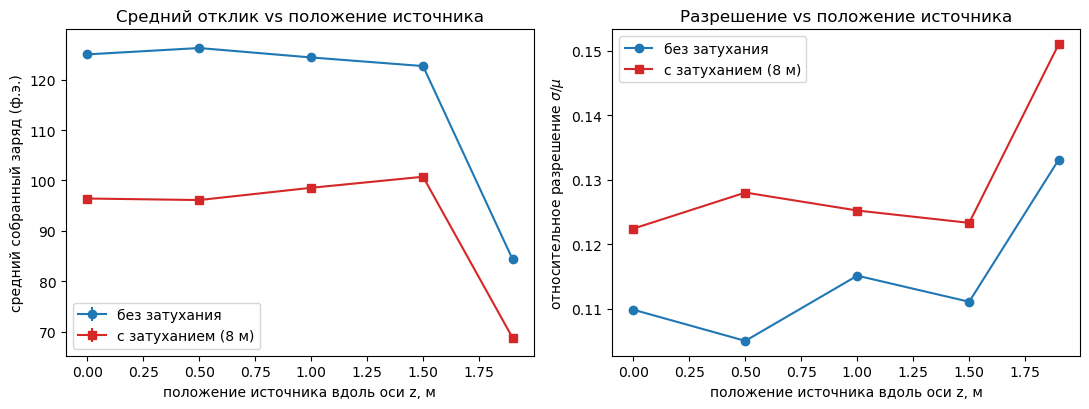

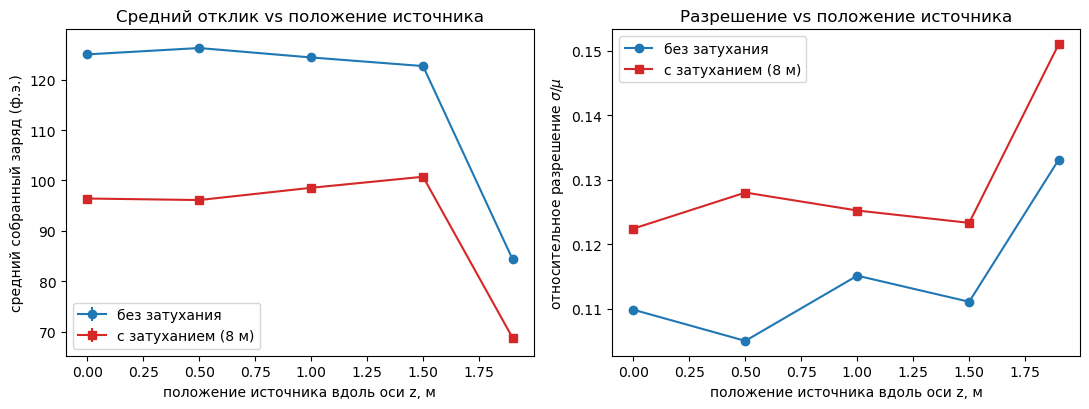

In [9]:
means_no_att = np.array([results_no_att[z].mean() for z in z_positions])
sems_no_att = np.array([results_no_att[z].std()/np.sqrt(n_events) for z in z_positions])
means_att = np.array([results_att[z].mean() for z in z_positions])
sems_att = np.array([results_att[z].std()/np.sqrt(n_events) for z in z_positions])

relres_no_att = np.array([results_no_att[z].std()/results_no_att[z].mean() for z in z_positions])
relres_att = np.array([results_att[z].std()/results_att[z].mean() for z in z_positions])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].errorbar(z_positions, means_no_att, yerr=sems_no_att, fmt='o-', color='tab:blue', label='без затухания')
axes[0].errorbar(z_positions, means_att, yerr=sems_att, fmt='s-', color='tab:red', label='с затуханием (8 м)')
axes[0].set_xlabel('положение источника вдоль оси z, м')
axes[0].set_ylabel('средний собранный заряд (ф.э.)')
axes[0].set_title('Средний отклик vs положение источника')
axes[0].legend()

axes[1].plot(z_positions, relres_no_att, 'o-', color='tab:blue', label='без затухания')
axes[1].plot(z_positions, relres_att, 's-', color='tab:red', label='с затуханием (8 м)')
axes[1].set_xlabel('положение источника вдоль оси z, м')
axes[1].set_ylabel(r'относительное разрешение $\sigma/\mu$')
axes[1].set_title('Разрешение vs положение источника')
axes[1].legend()

fig.tight_layout()
fig